# Basins of attraction: Newton's method on \(z^n - 1\)

This notebook explores one of the simplest dynamical systems you can write down:
repeatedly apply Newton's method to a polynomial and ask which root each starting
point ends up at.

* **Attractor:** a root of the polynomial.
* **Basin:** the set of starting points that converge to that root.
* **Settling time:** how many iterations it takes to get close.
* **The boundary** between basins can be a simple line or a fractal tangle,
  depending on \(n\).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from math_vis.basins import (
    basin_map, complex_grid, render_basins, render_fli,
    uncertainty_exponent, basin_entropy, normalize_iters,
)
from math_vis import finish

# Tests run this notebook as plain Python; keep resolutions modest there.
HIGH_RES = os.environ.get("PYTEST_CURRENT_TEST") is None
SIZE = 800 if HIGH_RES else 300

## \(n = 2\): the smooth control

For \(z^2 - 1\) the two basins are separated by the imaginary axis: a straight
line. The boundary has box-counting dimension \(D = 1\), so the uncertainty
exponent \(\alpha = 2 - D = 1\).

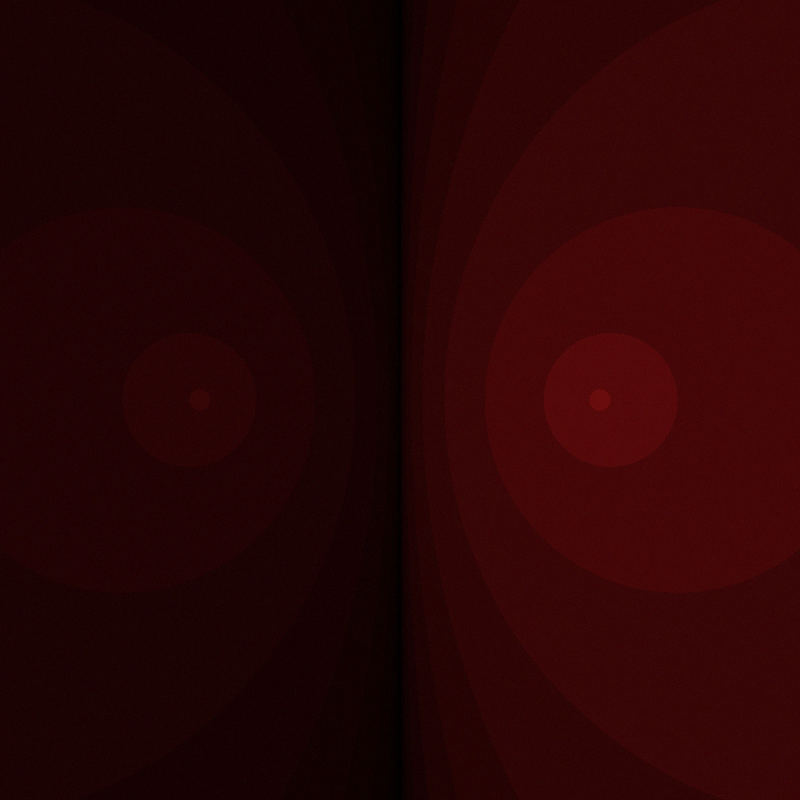

array([[[28,  2,  4],
        [28,  1,  3],
        [30,  4,  1],
        ...,
        [58,  6,  5],
        [55,  7,  7],
        [59,  7,  5]],

       [[31,  1,  2],
        [26,  0,  4],
        [25,  1,  4],
        ...,
        [59,  8,  6],
        [55,  7, 12],
        [57,  5,  4]],

       [[29,  0,  4],
        [29,  3,  2],
        [32,  3,  6],
        ...,
        [59,  4, 11],
        [55,  6,  9],
        [59,  7,  7]],

       ...,

       [[27,  1,  0],
        [24,  4,  3],
        [24,  1,  1],
        ...,
        [60,  0,  8],
        [56,  5,  6],
        [60,  6,  8]],

       [[27,  0,  6],
        [30,  4,  4],
        [30,  5,  2],
        ...,
        [55,  5,  6],
        [58,  5,  5],
        [59,  6,  7]],

       [[28,  1,  0],
        [27,  5,  0],
        [27,  4,  3],
        ...,
        [60,  5, 10],
        [59,  7,  6],
        [55,  3,  7]]], shape=(800, 800, 3), dtype=uint8)

In [2]:
z0 = complex_grid((-2, 2, -2, 2), (SIZE, SIZE))
basin, iters, fli = basin_map(z0, n=2, max_iter=60, tol=1e-6)
img_z2 = render_basins(basin, iters, palette=["#e41a1c", "#000000"], norm="log1p", gamma=0.7)
finish(img_z2, grain=2.0)


## \(n = 3\): three roots, tangled boundary

Add one more root and the boundary becomes a fractal. Zooming in does not make
it go away.

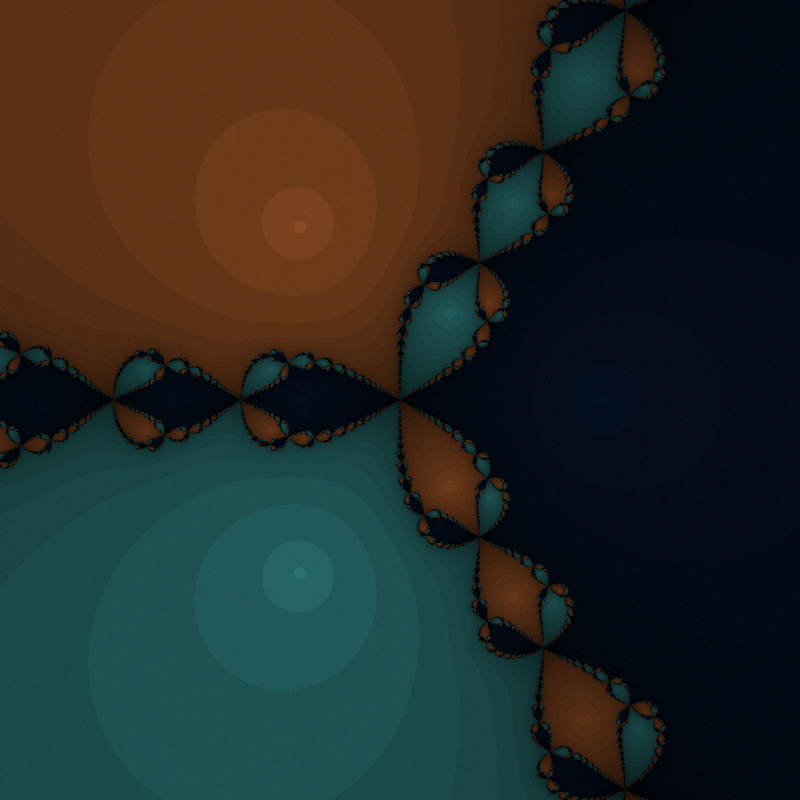

array([[[92, 48, 23],
        [92, 47, 22],
        [94, 50, 20],
        ...,
        [ 4,  9, 17],
        [ 1, 10, 19],
        [ 5, 10, 17]],

       [[95, 47, 21],
        [90, 46, 23],
        [89, 47, 23],
        ...,
        [ 5, 11, 18],
        [ 1, 10, 24],
        [ 3,  8, 16]],

       [[93, 46, 23],
        [93, 49, 21],
        [96, 49, 25],
        ...,
        [ 5,  7, 23],
        [ 1,  9, 21],
        [ 5, 10, 19]],

       ...,

       [[27, 73, 71],
        [24, 76, 75],
        [24, 73, 73],
        ...,
        [ 6,  3, 20],
        [ 2,  8, 18],
        [ 6,  9, 20]],

       [[27, 72, 78],
        [30, 76, 76],
        [30, 77, 74],
        ...,
        [ 1,  8, 18],
        [ 4,  8, 17],
        [ 5,  9, 19]],

       [[28, 73, 72],
        [27, 77, 72],
        [27, 76, 75],
        ...,
        [ 6,  8, 22],
        [ 5, 10, 18],
        [ 1,  6, 19]]], shape=(800, 800, 3), dtype=uint8)

In [3]:
basin3, iters3, fli3 = basin_map(z0, n=3, max_iter=80, tol=1e-6)
img_z3 = render_basins(basin3, iters3, norm="log1p", gamma=0.7)
finish(img_z3, grain=2.0)

## Fast Lyapunov indicator edge map

The FLI highlights places where the Newton map stretches nearby points apart —
exactly the basin boundary. It is a useful edge detector, but it has its own
limits: very slow regions and points that land on periodic cycles can also light
up.

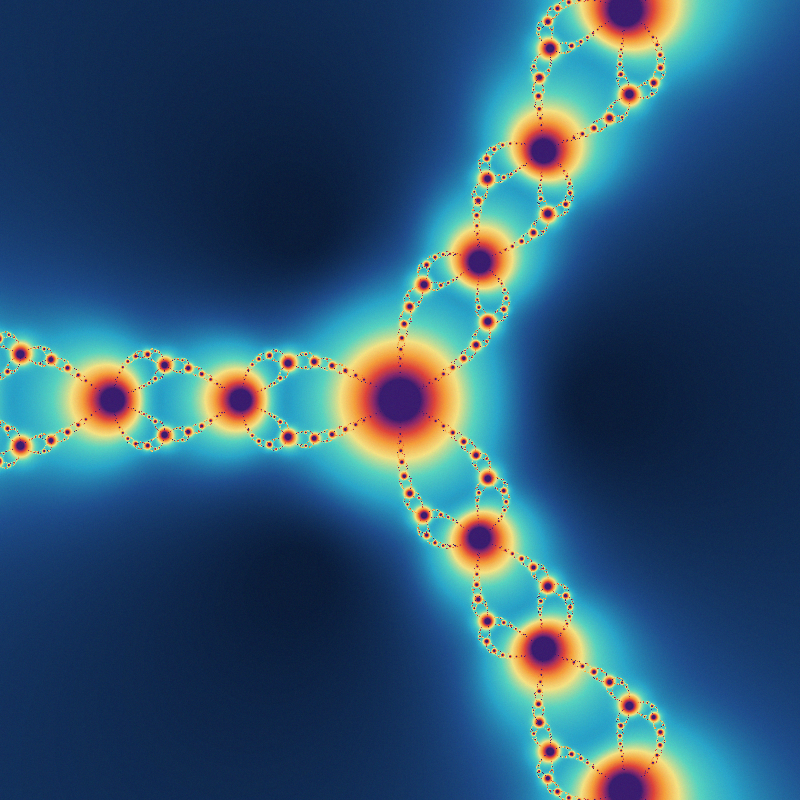

array([[[ 19,  47,  92],
        [ 19,  46,  91],
        [ 20,  49,  88],
        ...,
        [ 34,  95, 150],
        [ 31,  96, 152],
        [ 35,  95, 149]],

       [[ 22,  46,  90],
        [ 17,  45,  92],
        [ 15,  46,  91],
        ...,
        [ 35,  97, 151],
        [ 31,  95, 156],
        [ 33,  93, 148]],

       [[ 20,  45,  92],
        [ 20,  48,  90],
        [ 22,  48,  93],
        ...,
        [ 35,  92, 155],
        [ 31,  94, 153],
        [ 34,  94, 150]],

       ...,

       [[ 18,  46,  87],
        [ 15,  49,  91],
        [ 14,  46,  88],
        ...,
        [ 36,  88, 152],
        [ 32,  93, 150],
        [ 35,  93, 151]],

       [[ 18,  45,  94],
        [ 21,  49,  92],
        [ 20,  50,  89],
        ...,
        [ 31,  94, 151],
        [ 34,  93, 149],
        [ 35,  94, 151]],

       [[ 19,  46,  88],
        [ 18,  50,  88],
        [ 17,  49,  90],
        ...,
        [ 36,  94, 155],
        [ 35,  96, 151],
        [ 31,  91, 151]]

In [4]:
img_fli = render_fli(fli3, cmap=["#0b1d3a", "#1f4e8c", "#2aa5c9", "#58d3c0", "#f4e285", "#f59e3b", "#e0453a", "#8e2a6a", "#3a1d6e"])
finish(img_fli, grain=2.0)


## Metrics: putting a number on "tangled"

* **Uncertainty exponent \(\alpha\):** for a box size \(\varepsilon\), measure the
  fraction \(P_{\text{both}}(\varepsilon)\) of boxes that contain more than one basin.
  For a straight boundary \(P \sim \varepsilon^1\); for a fractal boundary the
  exponent is smaller because the boundary fills more boxes.
* **Basin entropy:** Shannon entropy of basin labels inside boxes, scanned over
  box sizes.
* **Fast Lyapunov indicator:** logarithmic growth of the Newton-map derivative.

All three are resolution-dependent, so the notebook will show both their
successes and their limits.

In [5]:
for n in [2, 3, 4]:
    b, _, _ = basin_map(z0, n=n, max_iter=80, tol=1e-6)
    res = uncertainty_exponent(b, box_sizes=[4, 8, 16, 32, 64])
    print(f"n={n}: alpha = {res['alpha']:.3f}")

n=2: alpha = 1.059
n=3: alpha = 0.592
n=4: alpha = 0.459


*This is a draft. More sections will follow: higher \(n\) contact sheets,
settling-time normalisation, a zoom sequence, the float32 precision lesson, and
a wall-art render.*